In [ ]:
# Cell 1: Install packages
!pip install -q "stable-baselines3[extra]" gymnasium arc-agi matplotlib rich tqdm

In [ ]:
# Cell 2: Imports & Setup with your ARC API Key
import sys
import os
import time
import warnings
import logging
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces

import torch
import torch.nn as nn
import torch.nn.functional as F

import arc_agi
from arc_agi import Arcade, OperationMode
from arcengine import GameAction, GameState

from stable_baselines3 import DQN
from stable_baselines3.common.callbacks import BaseCallback
from stable_baselines3.common.torch_layers import BaseFeaturesExtractor

# Set your ARC API key
ARC_API_KEY = "09f820fa-ec53-420d-8a2f-aacf2172bf7f"
os.environ["ARC_API_KEY"] = ARC_API_KEY

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch Device : {device.upper()}")
print(f"ARC API Key    : {ARC_API_KEY[:8]}...{ARC_API_KEY[-4:]} (Configured)")

PyTorch Device : CUDA
ARC API Key    : 09f820fa...bf7f (Configured)


In [ ]:
# Cell 3: Fast Local Environment with Episode Action Recording (Fixed)
class ARCLs20Level1PureEnv(gym.Env):
    metadata = {"render_modes": ["rgb_array"]}

    def __init__(self, operation_mode=OperationMode.NORMAL):
        super().__init__()
        api_key = os.environ.get("ARC_API_KEY", "")
        self.arc = Arcade(arc_api_key=api_key, operation_mode=operation_mode)
        self.game = self.arc.make("ls20", save_recording=False)

        if self.game is None:
            raise RuntimeError("Failed to load ls20 environment.")

        self.observation_space = spaces.Box(
            low=0, high=15, shape=(1, 64, 64), dtype=np.uint8
        )

        obs = self.game.reset()
        self.valid_actions = [
            a for a in self.game.action_space
            if a != GameAction.RESET and not a.is_complex()
        ]
        self.action_space = spaces.Discrete(len(self.valid_actions))

        try:
            self.human_baseline = self.game.environment_info.baseline_actions[0]
        except Exception:
            self.human_baseline = 22

        # Tracks actions of the current and last finished episode
        self.current_episode_actions = []
        self.last_completed_episode_actions = []

    def _get_obs(self, obs):
        if obs is None or not obs.frame or len(obs.frame) == 0:
            return np.zeros((1, 64, 64), dtype=np.uint8)
        return np.array(obs.frame[-1], dtype=np.uint8)[None, :, :]

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_episode_actions = []
        obs = self.game.reset()
        return self._get_obs(obs), {}

    def step(self, action_idx):
        action = self.valid_actions[action_idx]
        self.current_episode_actions.append(action)
        obs = self.game.step(action)

        reward = 0.0
        terminated = False
        truncated = False

        if obs is not None:
            if obs.levels_completed > 0 or obs.state == GameState.WIN:
                reward = 1.0
                terminated = True
            elif obs.state == GameState.GAME_OVER:
                reward = 0.0
                terminated = True

        # Save actions before SB3's auto-reset wipes current_episode_actions!
        if terminated or truncated:
            self.last_completed_episode_actions = list(self.current_episode_actions)

        return self._get_obs(obs), reward, terminated, truncated, {}

In [ ]:
# Cell 4: High-Efficiency CNN Feature Extractor (Fast on both CPU & GPU)
class ARCOneHotFeaturesExtractor(BaseFeaturesExtractor):
    def __init__(self, observation_space, features_dim=256):
        super().__init__(observation_space, features_dim)

        # 3-layer optimized CNN: 64x64 -> 32x32 -> 16x16 -> 8x8
        self.cnn = nn.Sequential(
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),  # 64 -> 32
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),  # 32 -> 16
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=2, padding=1),  # 16 -> 8
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4)),                            # 8 -> 4 (64 * 4 * 4 = 1024)
            nn.Flatten(),
        )
        self.linear = nn.Sequential(
            nn.Linear(64 * 4 * 4, features_dim),
            nn.ReLU()
        )

    def forward(self, observations: torch.Tensor) -> torch.Tensor:
        indices = observations.long().squeeze(1)  # (batch, 64, 64)
        one_hot = F.one_hot(indices, num_classes=16).permute(0, 3, 1, 2).float()
        return self.linear(self.cnn(one_hot))

In [ ]:
# Cell 5: Callback with Zero-Division Safe Replays
import sys
import os
import time

class ARCRHAEMilestoneCallback(BaseCallback):
    def __init__(self, train_env, eval_env, human_baseline, total_timesteps, eval_freq=500, max_eval_steps=300, verbose=0):
        super().__init__(verbose)
        self.train_env = train_env
        self.eval_env = eval_env
        self.human_baseline = human_baseline
        self.total_timesteps = total_timesteps
        self.eval_freq = eval_freq
        self.max_eval_steps = max_eval_steps
        self.start_time = None

        self.first_training_win_step = None
        self.training_wins = 0
        self.last_eval_str = "None"

        # 5 Key Milestones
        self.milestones = [
            {"id": "first_win", "name": "Milestone 1: First Completion", "min_rhae": 0.0,   "achieved": False, "rec": None},
            {"id": "rhae_25",   "name": "Milestone 2: Cross 25% RHAE",     "min_rhae": 25.0,  "achieved": False, "rec": None},
            {"id": "rhae_50",   "name": "Milestone 3: Cross 50% RHAE",     "min_rhae": 50.0,  "achieved": False, "rec": None},
            {"id": "rhae_75",   "name": "Milestone 4: Cross 75% RHAE",     "min_rhae": 75.0,  "achieved": False, "rec": None},
            {"id": "rhae_100",  "name": "Milestone 5: Achieve 100% RHAE",   "min_rhae": 100.0, "achieved": False, "rec": None},
        ]
        self.best_rhae = 0.0
        self.total_online_recordings = 0

    def _init_callback(self) -> None:
        self.start_time = time.time()

    def _replay_actions_online(self, actions_list, milestone_name):
        """Uploads and replays an exact sequence of actions to ARC Online."""
        try:
            api_key = os.environ.get("ARC_API_KEY", "")
            online_arc = Arcade(arc_api_key=api_key, operation_mode=OperationMode.ONLINE)
            card_id = online_arc.create_scorecard(tags=["milestone", milestone_name, "ls20"])
            online_game = online_arc.make("ls20", scorecard_id=card_id, save_recording=True, include_frame_data=True)

            if online_game is None:
                return {"success": False, "url": "Failed to create online session"}

            online_game.reset()
            steps = 0
            won = False

            for act in actions_list:
                obs = online_game.step(act)
                steps += 1
                if obs is not None and (obs.levels_completed > 0 or obs.state == GameState.WIN):
                    won = True
                    break

            try:
                online_arc.close_scorecard(card_id)
            except Exception:
                pass

            steps_safe = max(1, steps)
            rhae = min(1.15, (self.human_baseline / steps_safe) ** 2) * 100.0 if won else 0.0
            return {
                "success": True,
                "url": f"https://arcprize.org/scorecards/{card_id}",
                "steps": steps,
                "rhae": rhae,
                "won": won
            }
        except Exception as e:
            return {"success": False, "url": f"Online replay error: {e}"}

    def _evaluate_greedy(self):
        """Zero-epsilon evaluation on local environment."""
        obs, _ = self.eval_env.reset()
        steps = 0
        won = False
        action_sequence = []

        while steps < self.max_eval_steps:
            action_idx, _ = self.model.predict(obs, deterministic=True)
            action = self.eval_env.valid_actions[int(action_idx)]
            action_sequence.append(action)

            obs, reward, terminated, truncated, _ = self.eval_env.step(action_idx)
            steps += 1

            if reward > 0:
                won = True
                break
            if terminated or truncated:
                break

        steps_safe = max(1, steps)
        rhae = min(1.15, (self.human_baseline / steps_safe) ** 2) * 100.0 if won else 0.0
        return {"won": won, "steps": steps, "rhae": rhae, "actions": action_sequence}

    def _on_step(self) -> bool:
        # 1. Capture the VERY FIRST level completion during exploration
        for reward in self.locals["rewards"]:
            if reward > 0:
                self.training_wins += 1
                if not self.milestones[0]["achieved"]:
                    self.first_training_win_step = self.n_calls

                    # Read the preserved actions of the completed winning episode
                    winning_actions = list(self.train_env.last_completed_episode_actions)
                    steps_taken = max(1, len(winning_actions))
                    rhae = min(1.15, (self.human_baseline / steps_taken) ** 2) * 100.0

                    sys.stdout.write(f"\n🎉 [Step {self.n_calls}] UNLOCKED: Milestone 1: First Completion ({steps_taken} actions, RHAE: {rhae:.2f}%)\n")
                    sys.stdout.write("Uploading first-win replay to ARC Online...\n")
                    sys.stdout.flush()

                    rec_info = self._replay_actions_online(winning_actions, "first_win")
                    self.total_online_recordings += 1
                    self.milestones[0]["achieved"] = True
                    self.milestones[0]["rec"] = rec_info

                    sys.stdout.write(f"🔗 Scorecard: {rec_info.get('url')}\n")
                    sys.stdout.flush()

        # 2. Hold epsilon at 1.0 until goal is found, then decay smoothly to 50% floor
        if self.first_training_win_step is None:
            self.model.exploration_rate = 1.0
        else:
            steps_since_win = self.n_calls - self.first_training_win_step
            progress = min(1.0, steps_since_win / 30_000)
            self.model.exploration_rate = 1.0 - (progress * 0.50)

        # 3. Periodic Zero-Epsilon Evaluation (every 500 steps)
        if self.n_calls % self.eval_freq == 0:
            eval_res = self._evaluate_greedy()
            won = eval_res["won"]
            steps = eval_res["steps"]
            rhae = eval_res["rhae"]

            if rhae > self.best_rhae:
                self.best_rhae = rhae

            self.last_eval_str = f"WIN ({steps} acts, {rhae:.1f}%)" if won else f"{steps} acts (0%)"

            # Check milestones 2 through 5
            new_milestones = []
            if won:
                for m in self.milestones[1:]:
                    if not m["achieved"] and rhae >= m["min_rhae"]:
                        new_milestones.append(m)

            if new_milestones:
                primary = new_milestones[-1]
                sys.stdout.write(f"\n🎉 [Step {self.n_calls}] UNLOCKED: {primary['name']} (RHAE: {rhae:.2f}%)\n")
                sys.stdout.write("Uploading online replay to ARC...\n")
                sys.stdout.flush()

                rec_info = self._replay_actions_online(eval_res["actions"], primary["id"])
                self.total_online_recordings += 1

                for m in new_milestones:
                    m["achieved"] = True
                    m["rec"] = rec_info

                sys.stdout.write(f"🔗 Scorecard: {rec_info.get('url')}\n")
                sys.stdout.flush()

            # Halt when 100% RHAE is achieved
            if self.milestones[4]["achieved"] or rhae >= 100.0:
                sys.stdout.write(f"\n🏆 [Step {self.n_calls}] 100% RHAE ACHIEVED ({steps} actions)! Stopping run.\n")
                sys.stdout.flush()
                return False

        # 4. Progress Update (every 100 steps)
        if self.n_calls % 100 == 0:
            elapsed = time.time() - self.start_time
            fps = int(self.n_calls / max(elapsed, 1e-5))
            pct = (self.n_calls / self.total_timesteps) * 100
            current_eps = getattr(self.model, "exploration_rate", 0.50)
            eta_m = int((self.total_timesteps - self.n_calls) / max(fps, 1) / 60)

            bar_len = 20
            filled = int(bar_len * (self.n_calls / self.total_timesteps))
            bar = "█" * filled + "░" * (bar_len - filled)

            sys.stdout.write(
                f"\r[{bar}] {self.n_calls:>6d}/{self.total_timesteps} ({pct:4.1f}%) | "
                f"{fps:>3d} it/s | ETA: {eta_m:>2d}m | ε: {current_eps:.2f} | Eval: {self.last_eval_str} | Best: {self.best_rhae:4.1f}%"
            )
            sys.stdout.flush()

        return True

In [ ]:
# Cell 6: Clean DQN Training Run
TOTAL_TIMESTEPS = 150_000

train_env = ARCLs20Level1PureEnv()
eval_env = ARCLs20Level1PureEnv()

policy_kwargs = dict(
    features_extractor_class=ARCOneHotFeaturesExtractor,
    features_extractor_kwargs=dict(features_dim=256),
    normalize_images=False,
)

model = DQN(
    policy="CnnPolicy",
    env=train_env,
    policy_kwargs=policy_kwargs,
    learning_rate=5e-4,
    buffer_size=30_000,
    learning_starts=1_000,
    batch_size=64,
    gamma=0.99,
    train_freq=4,
    gradient_steps=1,
    target_update_interval=250,
    exploration_initial_eps=1.0,
    exploration_final_eps=0.50,
    verbose=0,
    device=device
)

milestone_tracker = ARCRHAEMilestoneCallback(
    train_env=train_env,
    eval_env=eval_env,
    human_baseline=train_env.human_baseline,
    total_timesteps=TOTAL_TIMESTEPS,
    eval_freq=500,               # Checks every 500 steps
    max_eval_steps=300
)

print(f"Training on {device.upper()} (Baseline: {train_env.human_baseline} actions)...")
model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    callback=milestone_tracker,
    progress_bar=False
)

INFO:arc_agi.scorecard:Initialized ScorecardManager with idle_for=0:15:00 and max_open_for=3 days, 0:00:00
2026-09-24 18:09:29 | INFO | Successfully fetched 25 environment(s) from API


INFO:arc_agi.base:Successfully fetched 25 environment(s) from API


2026-09-24 18:09:29 | INFO | Created new scorecard: 95370f8b-032b-46f2-8c6b-bc3eae5f3b4a


INFO:arc_agi.base:Created new scorecard: 95370f8b-032b-46f2-8c6b-bc3eae5f3b4a


2026-09-24 18:09:30 | INFO | Successfully fetched metadata for game ls20


...

2026-09-24 18:16:59 | INFO | Successfully reset game ls20-9607627b, guid=105b2457-8c1c-427e-8083-2efca07e2524, scorecard_id=3f9516ff-8d3f-4053-a013-76f8e4e98530


INFO:arc_agi.base:Successfully reset game ls20-9607627b, guid=105b2457-8c1c-427e-8083-2efca07e2524, scorecard_id=3f9516ff-8d3f-4053-a013-76f8e4e98530


2026-09-24 18:17:07 | INFO | Closed scorecard: 3f9516ff-8d3f-4053-a013-76f8e4e98530


INFO:arc_agi.base:Closed scorecard: 3f9516ff-8d3f-4053-a013-76f8e4e98530


🔗 Scorecard: https://arcprize.org/scorecards/3f9516ff-8d3f-4053-a013-76f8e4e98530

🏆 [Step 39500] 100% RHAE ACHIEVED (15 actions)! Stopping run.


In [ ]:
# Cell 7: Final Milestone Summary & Replay Links
print("\n" + "=" * 75)
print("ARC-AGI-3 MILESTONE RECORDING SUMMARY")
print("=" * 75)
print(f"Total Online Recordings Created: {milestone_tracker.total_online_recordings} / 5")
print(f"Human Baseline Target          : {train_env.human_baseline} actions")
print(f"Peak RHAE Achieved             : {milestone_tracker.best_rhae:.2f}%\n")

for m in milestone_tracker.milestones:
    status = "ACHIEVED" if m["achieved"] else "NOT REACHED"
    print(f"• {m['name']}: {status}")
    if m["achieved"] and m["rec"]:
        if m["rec"].get("success"):
            print(f"    Online Scorecard : {m['rec']['url']}")
            print(f"    Actions Taken    : {m['rec']['steps']}")
            print(f"    RHAE Score       : {m['rec']['rhae']:.2f}%")
        else:
            print(f"    Recording Note   : {m['rec'].get('url')}")
print("=" * 75)


ARC-AGI-3 MILESTONE RECORDING SUMMARY
Total Online Recordings Created: 3 / 5
Human Baseline Target          : 22 actions
Peak RHAE Achieved             : 115.00%

• Milestone 1: First Completion: ACHIEVED
    Online Scorecard : https://arcprize.org/scorecards/69084f04-34a3-4463-afc3-e4d43d66582c
    Actions Taken    : 132
    RHAE Score       : 2.78%
• Milestone 2: Cross 25% RHAE: ACHIEVED
    Online Scorecard : https://arcprize.org/scorecards/e3ac1ce9-2736-414a-b849-5666a3714528
    Actions Taken    : 23
    RHAE Score       : 91.49%
• Milestone 3: Cross 50% RHAE: ACHIEVED
    Online Scorecard : https://arcprize.org/scorecards/e3ac1ce9-2736-414a-b849-5666a3714528
    Actions Taken    : 23
    RHAE Score       : 91.49%
• Milestone 4: Cross 75% RHAE: ACHIEVED
    Online Scorecard : https://arcprize.org/scorecards/e3ac1ce9-2736-414a-b849-5666a3714528
    Actions Taken    : 23
    RHAE Score       : 91.49%
• Milestone 5: Achieve 100% RHAE: ACHIEVED
    Online Scorecard : https://arcprize

PHASE 1: RUNNING RANDOM AGENT BASELINE (5 SEEDS)
INFO:arc_agi.scorecard:Initialized ScorecardManager with idle_for=0:15:00 and max_open_for=3 days, 0:00:00
2026-09-24 19:07:05 | INFO | Successfully fetched 25 environment(s) from API


INFO:arc_agi.base:Successfully fetched 25 environment(s) from API


2026-09-24 19:07:05 | INFO | Created new scorecard: 46843455-ad39-484f-b224-1e3474075502


INFO:arc_agi.base:Created new scorecard: 46843455-ad39-484f-b224-1e3474075502


2026-09-24 19:07:06 | INFO | Successfully fetched metadata for game ls20


...

2026-09-24 19:50:32 | INFO | Created new scorecard: 51128d1c-0066-437b-b20f-5bd0d3b9d434


INFO:arc_agi.base:Created new scorecard: 51128d1c-0066-437b-b20f-5bd0d3b9d434


2026-09-24 19:50:33 | INFO | Successfully fetched metadata for game ls20


INFO:arc_agi.base:Successfully fetched metadata for game ls20


  Seed 5/5 [████░░░░░░░░░░░░░░░░] 13700/60000 (22.8%) | 192 it/s | ε: 0.59 | Cumulative Wins: 0   
  [Seed 5] 🎯 1st Win encountered at action 13797 (ε was 0.59)! Policy begins exploiting.
  Seed 5/5 [████████████████████] 60000/60000 (100.0%) | 140 it/s | ε: 0.10 | Cumulative Wins: 167 

Generating final plot...


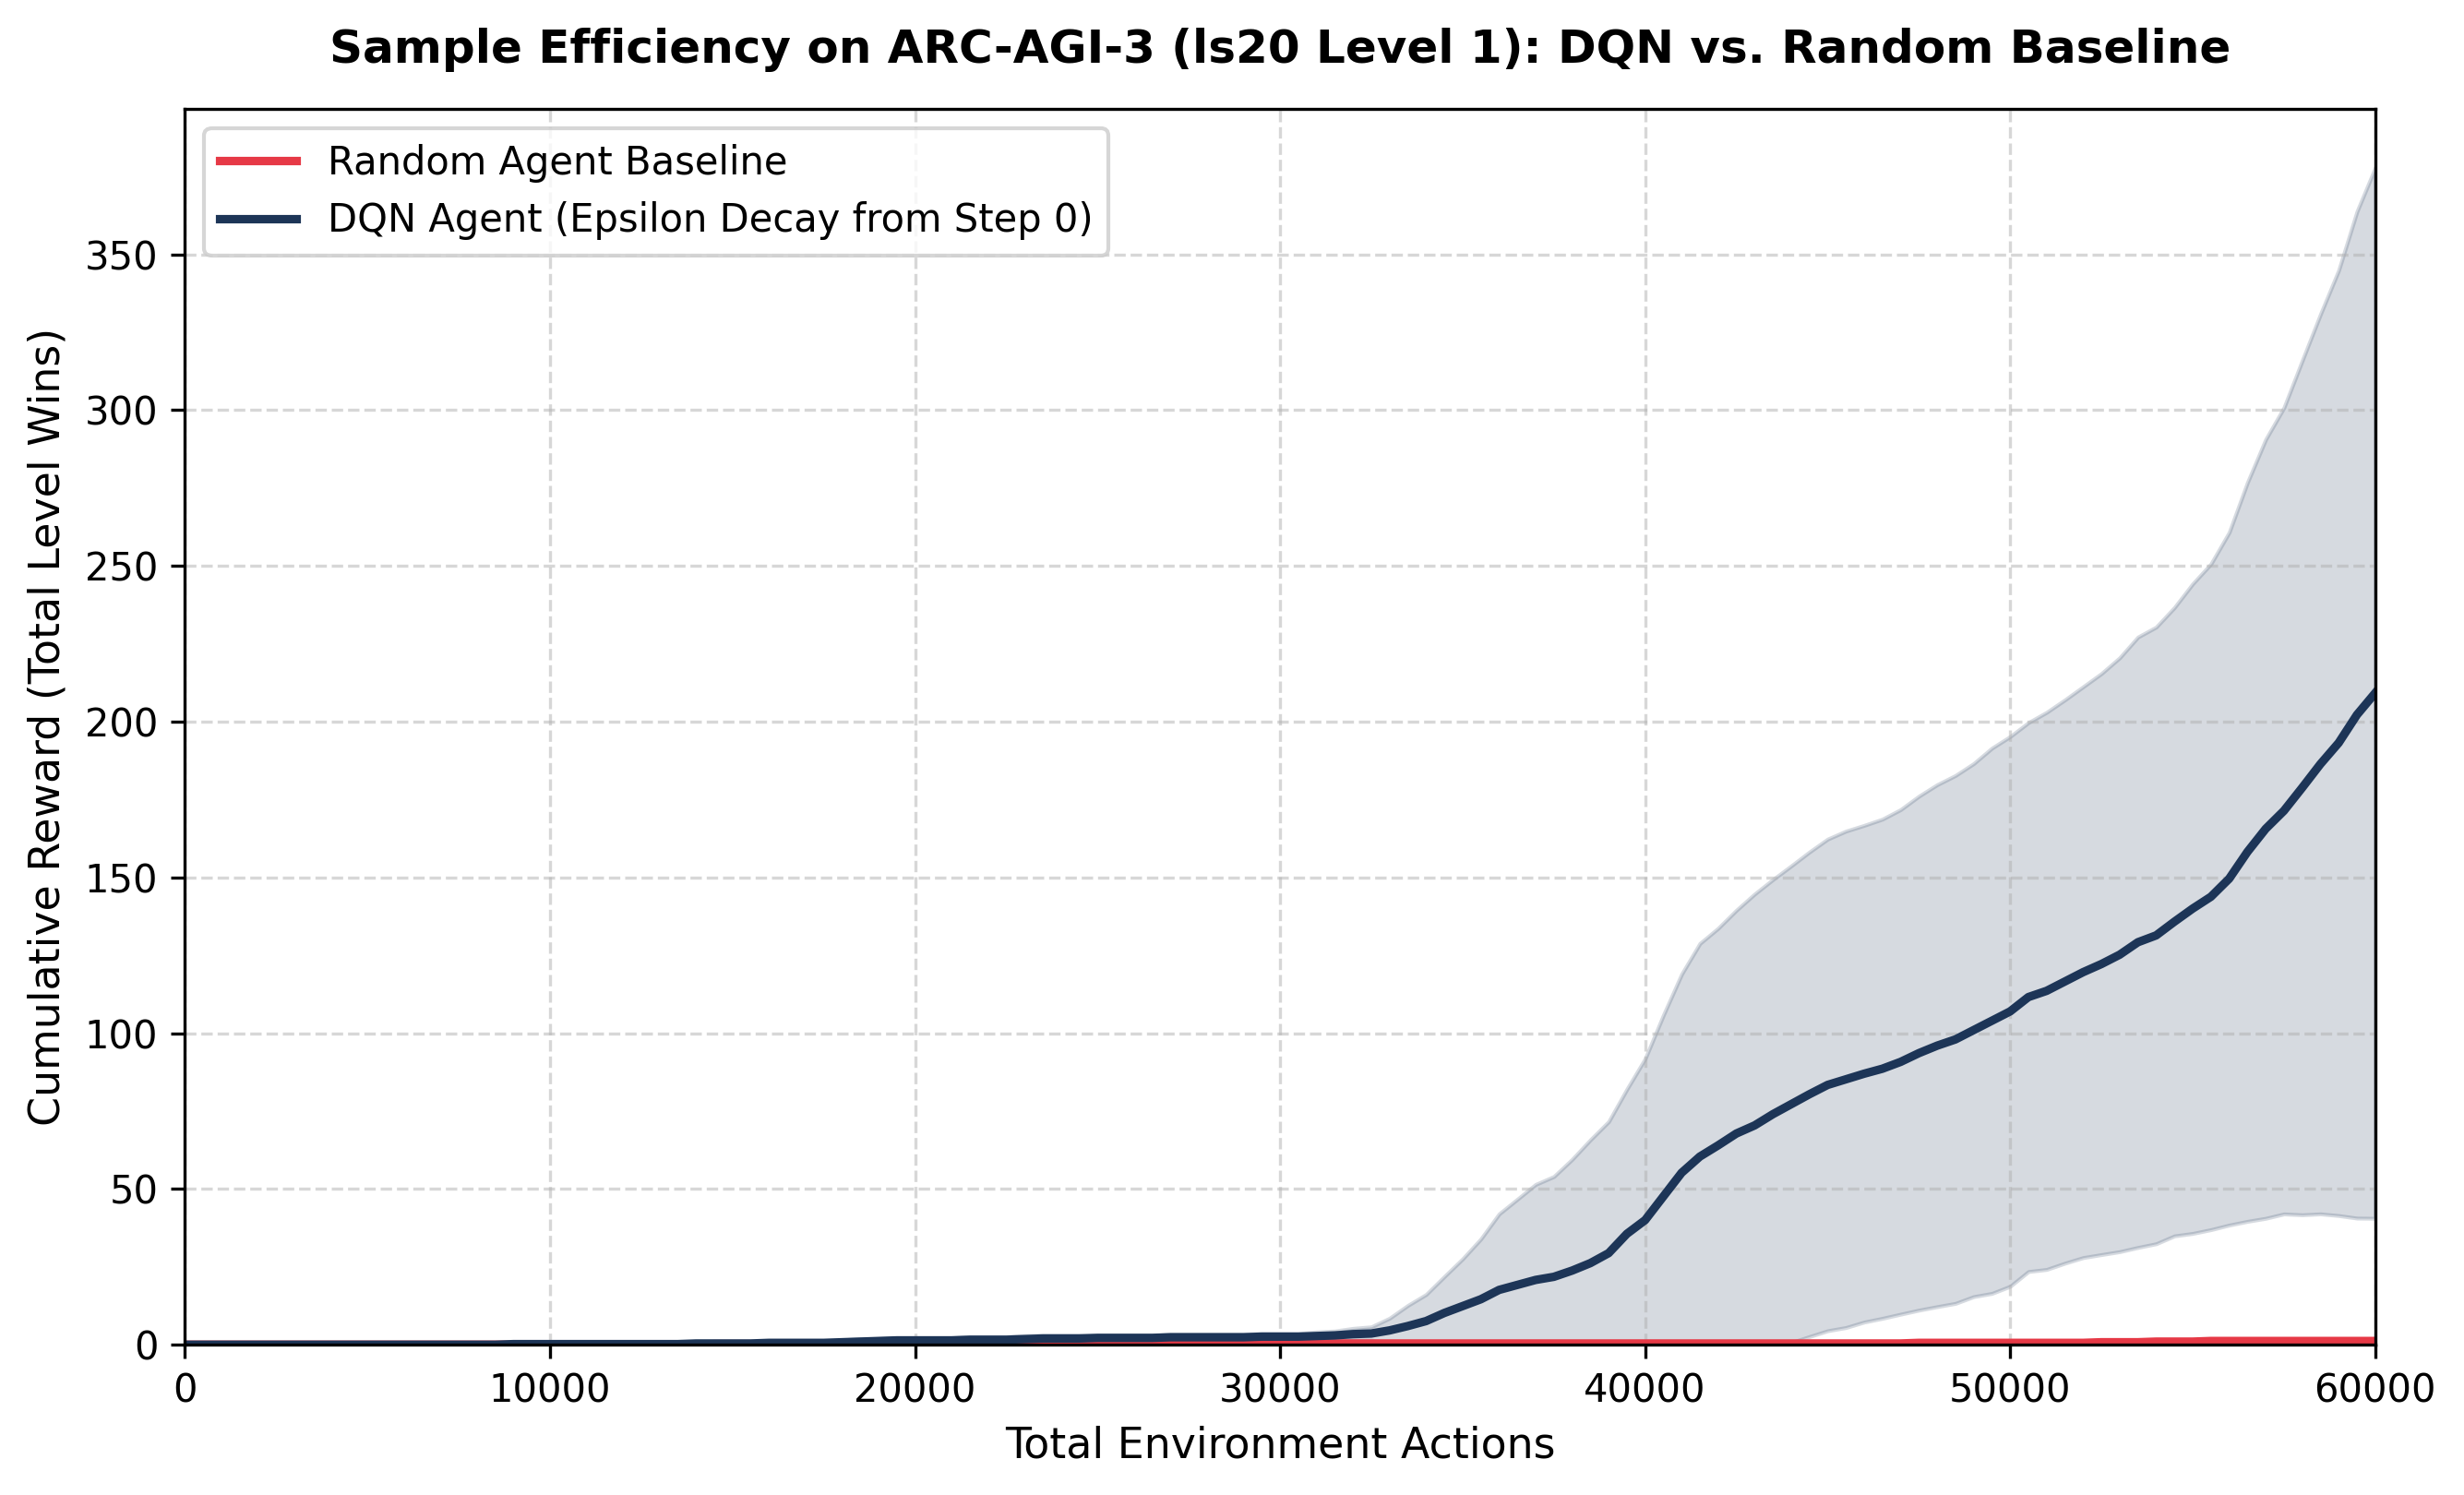

Plot saved as 'thesis_dqn_vs_random_decay.png'!


In [ ]:
# ==============================================================================
# THESIS EXPERIMENT: RANDOM vs. DQN (Standard Epsilon Decay from Step 0)
# ==============================================================================
import sys
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from stable_baselines3 import DQN
from stable_baselines3.common.callbacks import BaseCallback

SEEDS = 5                      # Standard 5-seed benchmark
MAX_STEPS = 60_000             # 60k steps ensures we capture the first win & divergence
SAMPLE_FREQ = 500              # Plot data points every 500 actions
steps_x = np.arange(0, MAX_STEPS + 1, SAMPLE_FREQ)

random_runs = np.zeros((SEEDS, len(steps_x)))
dqn_runs    = np.zeros((SEEDS, len(steps_x)))

# ==============================================================================
# 1. RANDOM AGENT EXPERIMENT (5 SEEDS)
# ==============================================================================
print("=" * 75)
print("PHASE 1: RUNNING RANDOM AGENT BASELINE (5 SEEDS)")
print("=" * 75)

for s in range(SEEDS):
    env = ARCLs20Level1PureEnv()
    env.reset(seed=s)
    np.random.seed(s)

    total_reward = 0
    history = [0]
    start_time = time.time()
    first_win_step = None

    for step in range(1, MAX_STEPS + 1):
        action = np.random.choice(env.action_space.n)
        _, reward, terminated, truncated, _ = env.step(action)

        if reward > 0:
            total_reward += reward
            if first_win_step is None:
                first_win_step = step
                sys.stdout.write(f"\n  [Seed {s+1}] 🎯 1st Win encountered at action {step}!\n")
                sys.stdout.flush()

        if terminated or truncated:
            env.reset()

        # Record data point for graph
        if step % SAMPLE_FREQ == 0:
            history.append(total_reward)

        # Live Progress Tracker (every 200 actions)
        if step % 200 == 0 or step == MAX_STEPS:
            elapsed = time.time() - start_time
            fps = int(step / max(elapsed, 1e-5))
            pct = (step / MAX_STEPS) * 100
            bar = "█" * int(20 * (step / MAX_STEPS)) + "░" * (20 - int(20 * (step / MAX_STEPS)))

            sys.stdout.write(
                f"\r  Seed {s+1}/{SEEDS} [{bar}] {step:>5d}/{MAX_STEPS} ({pct:4.1f}%) | "
                f"{fps:>3d} it/s | Cumulative Wins: {int(total_reward):<4d}"
            )
            sys.stdout.flush()

    random_runs[s] = history
    sys.stdout.write("\n")

# ==============================================================================
# 2. DQN AGENT EXPERIMENT (5 SEEDS, Epsilon Decays from Step 0)
# ==============================================================================
print("\n" + "=" * 75)
print("PHASE 2: RUNNING DQN AGENT (Decaying ε: 1.0 -> 0.10 from Step 0)")
print("=" * 75)

for s in range(SEEDS):
    torch.manual_seed(s)
    np.random.seed(s)

    train_env = ARCLs20Level1PureEnv()

    policy_kwargs = dict(
        features_extractor_class=ARCOneHotFeaturesExtractor,
        features_extractor_kwargs=dict(features_dim=256),
        normalize_images=False,
    )

    # Standard DQN setup: Epsilon decays from step 0 across 50% of the training run
    model = DQN(
        policy="CnnPolicy",
        env=train_env,
        policy_kwargs=policy_kwargs,
        learning_rate=5e-4,
        buffer_size=30_000,
        learning_starts=1_000,
        batch_size=64,
        gamma=0.99,
        train_freq=4,
        target_update_interval=250,
        exploration_fraction=0.50,     # Decays linearly from step 0 to step 30,000
        exploration_initial_eps=1.0,   # Starts at 100% random
        exploration_final_eps=0.10,    # Floors at 10%
        verbose=0,
        device=device,
        seed=s
    )

    # Custom Callback for Live Tracking & Graph History Recording
    class DQNExperimentTracker(BaseCallback):
        def __init__(self, seed_idx):
            super().__init__()
            self.seed_idx = seed_idx
            self.total_reward = 0
            self.first_win_step = None
            self.history = [0]
            self.start_time = None

        def _init_callback(self) -> None:
            self.start_time = time.time()

        def _on_step(self) -> bool:
            for r in self.locals["rewards"]:
                if r > 0:
                    self.total_reward += r
                    if self.first_win_step is None:
                        self.first_win_step = self.n_calls
                        current_eps = getattr(self.model, "exploration_rate", 0.0)
                        sys.stdout.write(
                            f"\n  [Seed {self.seed_idx+1}] 🎯 1st Win encountered at action {self.n_calls} "
                            f"(ε was {current_eps:.2f})! Policy begins exploiting.\n"
                        )
                        sys.stdout.flush()

            # Record data point for graph
            if self.n_calls % SAMPLE_FREQ == 0:
                self.history.append(self.total_reward)

            # Live Progress Tracker (every 100 steps)
            if self.n_calls % 100 == 0 or self.n_calls == MAX_STEPS:
                elapsed = time.time() - self.start_time
                fps = int(self.n_calls / max(elapsed, 1e-5))
                pct = (self.n_calls / MAX_STEPS) * 100
                current_eps = getattr(self.model, "exploration_rate", 0.10)
                bar = "█" * int(20 * (self.n_calls / MAX_STEPS)) + "░" * (20 - int(20 * (self.n_calls / MAX_STEPS)))

                sys.stdout.write(
                    f"\r  Seed {self.seed_idx+1}/{SEEDS} [{bar}] {self.n_calls:>5d}/{MAX_STEPS} ({pct:4.1f}%) | "
                    f"{fps:>3d} it/s | ε: {current_eps:.2f} | Cumulative Wins: {int(self.total_reward):<4d}"
                )
                sys.stdout.flush()
            return True

    tracker = DQNExperimentTracker(seed_idx=s)
    model.learn(total_timesteps=MAX_STEPS, callback=tracker, progress_bar=False)

    dqn_runs[s] = tracker.history
    sys.stdout.write("\n")

# ==============================================================================
# 3. THESIS PUBLICATION PLOT
# ==============================================================================
print("\nGenerating final plot...")

plt.figure(figsize=(9, 5.5), dpi=300)

# Random Agent Mean & Shaded Std Dev
r_mean = np.mean(random_runs, axis=0)
r_std  = np.std(random_runs, axis=0)
plt.plot(steps_x, r_mean, label="Random Agent Baseline", color="#E63946", lw=2.2)
plt.fill_between(steps_x, np.maximum(0, r_mean - r_std), r_mean + r_std, color="#E63946", alpha=0.18)

# DQN Agent Mean & Shaded Std Dev
d_mean = np.mean(dqn_runs, axis=0)
d_std  = np.std(dqn_runs, axis=0)
plt.plot(steps_x, d_mean, label="DQN Agent (Epsilon Decay from Step 0)", color="#1D3557", lw=2.2)
plt.fill_between(steps_x, np.maximum(0, d_mean - d_std), d_mean + d_std, color="#1D3557", alpha=0.18)

# Annotations & Styling
plt.title("Sample Efficiency on ARC-AGI-3 (ls20 Level 1): DQN vs. Random Baseline", fontsize=12, fontweight="bold", pad=12)
plt.xlabel("Total Environment Actions", fontsize=11)
plt.ylabel("Cumulative Reward (Total Level Wins)", fontsize=11)
plt.xlim(0, MAX_STEPS)
plt.ylim(bottom=0)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left", frameon=True, fontsize=10)

plt.tight_layout()
plt.savefig("thesis_dqn_vs_random_decay.png", dpi=300)
plt.show()

print("Plot saved as 'thesis_dqn_vs_random_decay.png'!")